# 01 · Data quality control

Code for: El Farchouni, A., et al. *Groundwater Recharge Mechanisms in the Haouz-Mejjate Aquifer (Morocco): Insights from Environmental Tracers and Self-Organizing Maps.* Groundwater for Sustainable Development, 101706. https://doi.org/10.1016/j.gsd.2026.101706

**What this notebook does**
1. Loads the compiled dataset: 540 water samples (74 collected for this study, 466 compiled from published studies), 29 columns.
2. Checks missing values per column and per data source.
3. Keeps the **406 samples with all seven major ions** (Ca²⁺, Mg²⁺, Na⁺, K⁺, HCO₃⁻, Cl⁻, SO₄²⁻), used for PCA, HCA and SOM.

| | |
|---|---|
| **Input** | `data/All_data1.xlsx` |
| **Output** | `outputs/intermediate/data_complete_major_ions.xlsx` (406 samples) |
| **Figures** | `outputs/figures/QC_*` (quality-control figures, not in the article) |
| **Next notebook** | `02_preprocessing.ipynb` |

**Methodological choices**
- **No imputation.** Multivariate analyses cannot be reliably performed on incomplete records (Haselbeck et al., 2019), so incomplete samples are removed, not gap-filled.
- **No outlier removal.** Extreme concentrations can be real geochemical end-members; all complete samples are kept, as in Haselbeck et al. (2019) and Bastianoni et al. (2021).
- **All water types kept** (groundwater, springs, streams, snow, rain, ...): they help the clustering separate recharge sources and mixing zones.
- The ionic charge balance error (ICBE, Eq. 1 of the article) is not recomputed here.

### <font color='orange'> **1) Packages, settings and paths** </font>

In [1]:
# ── Packages ─────────────────────────────────────────────────────────
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.patches import Patch
from pathlib import Path
import warnings

# ── Settings ─────────────────────────────────────────────────────────
warnings.filterwarnings("ignore", category=UserWarning)
plt.rcParams.update({
    "figure.dpi": 150,
    "savefig.dpi": 300,
    "font.size": 13,
    "axes.labelsize": 15,
    "axes.titlesize": 16,
    "axes.labelweight": "bold",
    "xtick.labelsize": 12,
    "ytick.labelsize": 12,
    "legend.fontsize": 12,
    "legend.title_fontsize": 13,
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "axes.edgecolor": "black",
    "axes.grid": True,
    "grid.alpha": 0.3,
    "savefig.bbox": "tight",
    "savefig.transparent": False,
})

# ── Paths (built from the repository root, so they work on any computer) ──
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / "data").is_dir() and (p / "notebooks").is_dir())
DATA_FILE    = ROOT / "data" / "All_data1.xlsx"
DIR_INTERMED = ROOT / "outputs" / "intermediate"
DIR_FIGURES  = ROOT / "outputs" / "figures"
for d in (DIR_INTERMED, DIR_FIGURES):
    d.mkdir(parents=True, exist_ok=True)

print("Package versions:")
for name, mod in [("numpy", np), ("pandas", pd), ("matplotlib", matplotlib), ("seaborn", sns)]:
    print(f"  {name:12s} {mod.__version__}")
print(f"\nData file : {DATA_FILE.relative_to(ROOT)}  (exists: {DATA_FILE.is_file()})")

C:\Users\Admin\anaconda3\Lib\site-packages\pandas\core\arrays\masked.py:60: UserWarning: Pandas requires version '1.3.6' or newer of 'bottleneck' (version '1.3.5' currently installed).
  from pandas.core import (


Package versions:
  numpy        1.26.4
  pandas       2.2.3
  matplotlib   3.7.2
  seaborn      0.12.2

Data file : data\All_data1.xlsx  (exists: True)


### <font color='orange'> **2) Load the data** </font>

In [2]:
# ── Load raw data ────────────────────────────────────────────────────
df_raw = pd.read_excel(DATA_FILE, sheet_name="Sheet1")

print(f"Dataset shape: {df_raw.shape[0]} samples × {df_raw.shape[1]} columns\n")

# ── Column overview ──────────────────────────────────────────────────
print(f"{'#':>3}  {'Column':<25s} {'Dtype':<12s} {'Non-null':>8s}  {'Missing':>7s}")
print("─" * 60)
for i, col in enumerate(df_raw.columns):
    nn = df_raw[col].notna().sum()
    na = df_raw[col].isna().sum()
    print(f"{i:3d}  {col:<25s} {str(df_raw[col].dtype):<12s} {nn:>8d}  {na:>7d}")

print(f"\n── Sample types ───────────────────────────────────────────")
print(df_raw["Type"].value_counts().to_string())

print(f"\n── Data sources ───────────────────────────────────────────")
for ref in df_raw["Reference"].unique():
    n = (df_raw["Reference"] == ref).sum()
    print(f"  {ref:<40s} ({n} samples)")

Dataset shape: 540 samples × 29 columns

  #  Column                    Dtype        Non-null  Missing
────────────────────────────────────────────────────────────
  0  Reference                 object            540        0
  1  SampleID                  object            540        0
  2  X                         float64           454       86
  3  Y                         float64           454       86
  4  Z                         float64           308      232
  5  depth to water (m)        float64           266      274
  6  Total Depth(m)            object             65      475
  7  Sampling date             object            540        0
  8  Sample                    object             74      466
  9  Type                      object            540        0
 10  Ca (mg/L)                 float64           410      130
 11  Mg (mg/L)                 float64           407      133
 12  Na (mg/L)                 float64           409      131
 13  K (mg/L)                 

### <font color='orange'> **3) Major ions: availability and summary** </font>

In [3]:
# ── Define major ion columns (required for SOM) ─────────────────────
MAJOR_IONS = ["Ca (mg/L)", "Mg (mg/L)", "Na (mg/L)", "K (mg/L)",
              "HCO3 (mg/L)", "Cl (mg/L)", "SO4 (mg/L)"]

# ── Verify all required columns are present ──────────────────────────
missing_cols = [c for c in MAJOR_IONS if c not in df_raw.columns]
if missing_cols:
    print(f"⚠ MISSING COLUMNS: {missing_cols}")
else:
    print("✓ All 7 major ion columns found in dataset.\n")

# ── Preview first rows ──────────────────────────────────────────────
ID_COLS = ["SampleID", "Type", "Reference"]
display(df_raw[ID_COLS + MAJOR_IONS].head(10))

# ── Major ions summary statistics ────────────────────────────────────
print("\n── Major ions descriptive statistics (mg/L) ────────────────")
display(df_raw[MAJOR_IONS].describe().round(2))

# ── Missing values in major ions ─────────────────────────────────────
print("\n── Missing values in major ions ────────────────────────────")
na_ions = df_raw[MAJOR_IONS].isnull().sum()
print(na_ions.to_string())
print(f"\nSamples with ALL 7 major ions available: "
      f"{df_raw[MAJOR_IONS].dropna().shape[0]} / {df_raw.shape[0]}")

✓ All 7 major ion columns found in dataset.



,SampleID,Type,Reference,Ca (mg/L),Mg (mg/L),Na (mg/L),K (mg/L),HCO3 (mg/L),Cl (mg/L),SO4 (mg/L)
0,S1,Snow,"(EL FARCHOUNI et al., 2025)",NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,S2,Snow,"(EL FARCHOUNI et al., 2025)",NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,S3,Snow,"(EL FARCHOUNI et al., 2025)",NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,S4,Snow,"(EL FARCHOUNI et al., 2025)",NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,S5,Lac,"(EL FARCHOUNI et al., 2025)",26.4,2.88,75.0,1.0,274.5,14.20,3.460
5,S6,Spring,"(EL FARCHOUNI et al., 2025)",48.0,4.80,5.0,5.0,164.7,3.55,3.249
6,S7,Spring,"(EL FARCHOUNI et al., 2025)",140.8,4.80,10.0,10.0,427.0,7.10,27.690
7,S8,Spring,"(EL FARCHOUNI et al., 2025)",51.2,7.68,5.0,2.0,170.8,7.10,12.520
8,S9,Spring,"(EL FARCHOUNI et al., 2025)",88.0,12.96,10.0,5.0,262.3,10.65,13.580
9,S10,Stream,"(EL FARCHOUNI et al., 2025)",32.0,5.28,5.0,2.0,122.0,14.20,10.620



── Major ions descriptive statistics (mg/L) ────────────────


,Ca (mg/L),Mg (mg/L),Na (mg/L),K (mg/L),HCO3 (mg/L),Cl (mg/L),SO4 (mg/L)
count,410.00,407.00,409.00,410.00,410.00,458.00,410.00
mean,99.98,62.18,111.93,233.53,290.07,179.66,153.01
std,69.48,414.46,179.10,747.62,122.43,296.16,494.70
min,0.90,0.04,0.10,0.00,4.00,0.20,0.05
25%,56.41,13.20,25.00,1.14,218.25,17.75,27.72
50%,85.00,28.71,58.36,2.08,293.12,71.40,60.40
75%,120.20,53.34,115.00,5.10,370.62,224.98,129.26
max,434.00,8354.00,1326.56,5603.00,762.50,2266.25,7789.00



── Missing values in major ions ────────────────────────────
Ca (mg/L)      130
Mg (mg/L)      133
Na (mg/L)      131
K (mg/L)       130
HCO3 (mg/L)    130
Cl (mg/L)       82
SO4 (mg/L)     130

Samples with ALL 7 major ions available: 406 / 540


### <font color='orange'> **4) Missing values** </font>

#### 4.1 Overview (quality-control figure, not in the article)

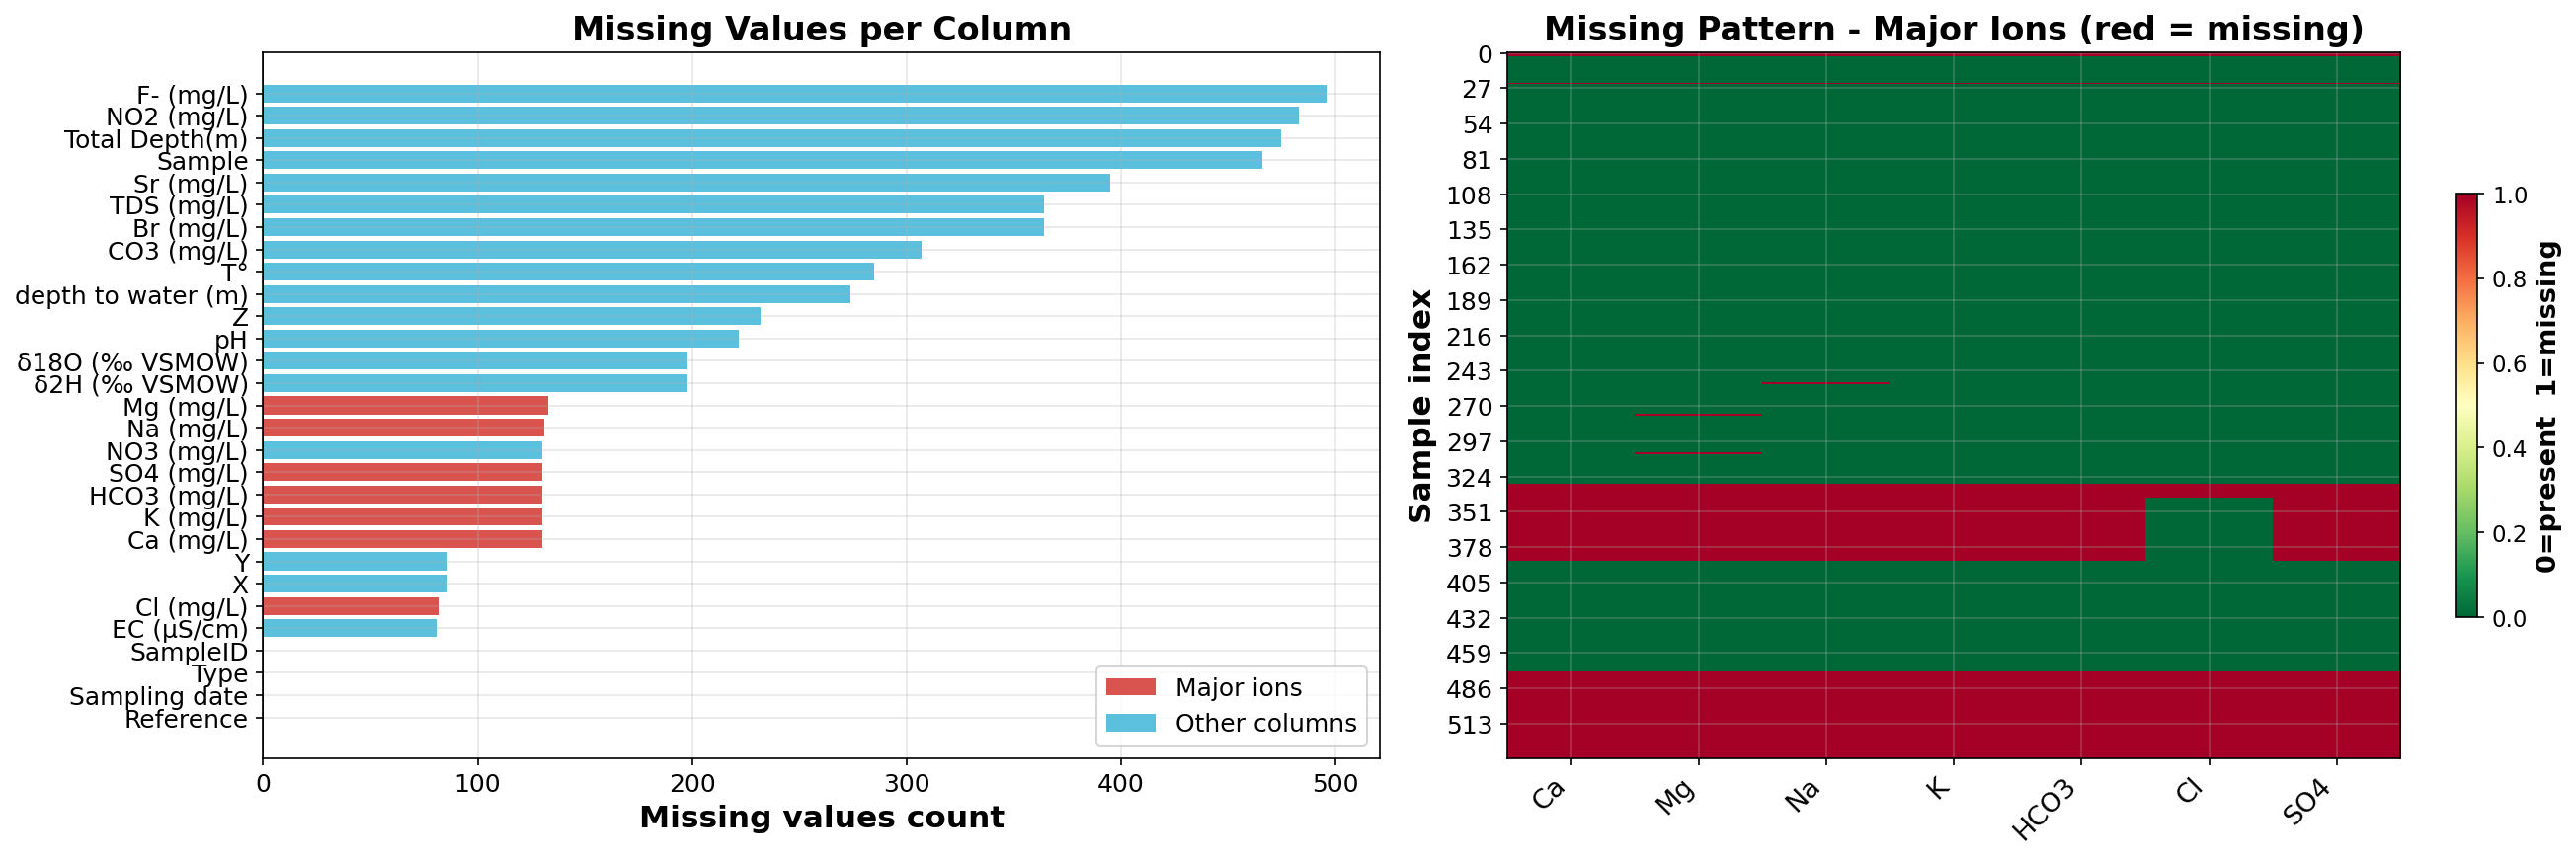

In [4]:
# ── 3.1  Missing values overview ──────────────────────────────────────

# --- (a) Bar chart: missing count per column ---
fig, axes = plt.subplots(1, 2, figsize=(18, 6))

na_counts = df_raw.isnull().sum().sort_values(ascending=False)
colors = ["#D9534F" if c in MAJOR_IONS else "#5BC0DE" for c in na_counts.index]

axes[0].barh(na_counts.index, na_counts.values, color=colors)
axes[0].set_xlabel("Missing values count", fontsize=15, fontweight="bold")
axes[0].set_title("Missing Values per Column", fontsize=16, fontweight="bold")
axes[0].tick_params(axis="both", labelsize=12)
axes[0].invert_yaxis()
axes[0].axvline(x=0, color="black", linewidth=0.8)
# Legend
axes[0].legend(handles=[Patch(facecolor="#D9534F", label="Major ions"),
                         Patch(facecolor="#5BC0DE", label="Other columns")],
               loc="lower right", fontsize=12)

# --- (b) Heatmap: missing pattern (major ions only) ---
cols_to_show = ["SampleID", "Type"] + MAJOR_IONS
df_heatmap = df_raw[cols_to_show].copy()
missing_matrix = df_heatmap[MAJOR_IONS].isnull().astype(int)

im = axes[1].imshow(missing_matrix.values, aspect="auto", cmap="RdYlGn_r",
                     interpolation="nearest", vmin=0, vmax=1)
axes[1].set_yticks(range(0, len(missing_matrix), max(1, len(missing_matrix)//20)))
axes[1].set_xticks(range(len(MAJOR_IONS)))
axes[1].set_xticklabels([c.replace(" (mg/L)", "") for c in MAJOR_IONS],
                         rotation=45, ha="right", fontsize=13)
axes[1].tick_params(axis="y", labelsize=12)
axes[1].set_ylabel("Sample index", fontsize=15, fontweight="bold")
axes[1].set_title("Missing Pattern - Major Ions (red = missing)",
                   fontsize=16, fontweight="bold")
cbar = fig.colorbar(im, ax=axes[1], shrink=0.6, label="0=present  1=missing")
cbar.ax.tick_params(labelsize=11)
cbar.set_label("0=present  1=missing", fontsize=13)

plt.tight_layout()
plt.savefig(DIR_FIGURES / "QC_missing_values_overview.png")
plt.show()

#### 4.2 Missing values per data source (quality-control figure, not in the article)

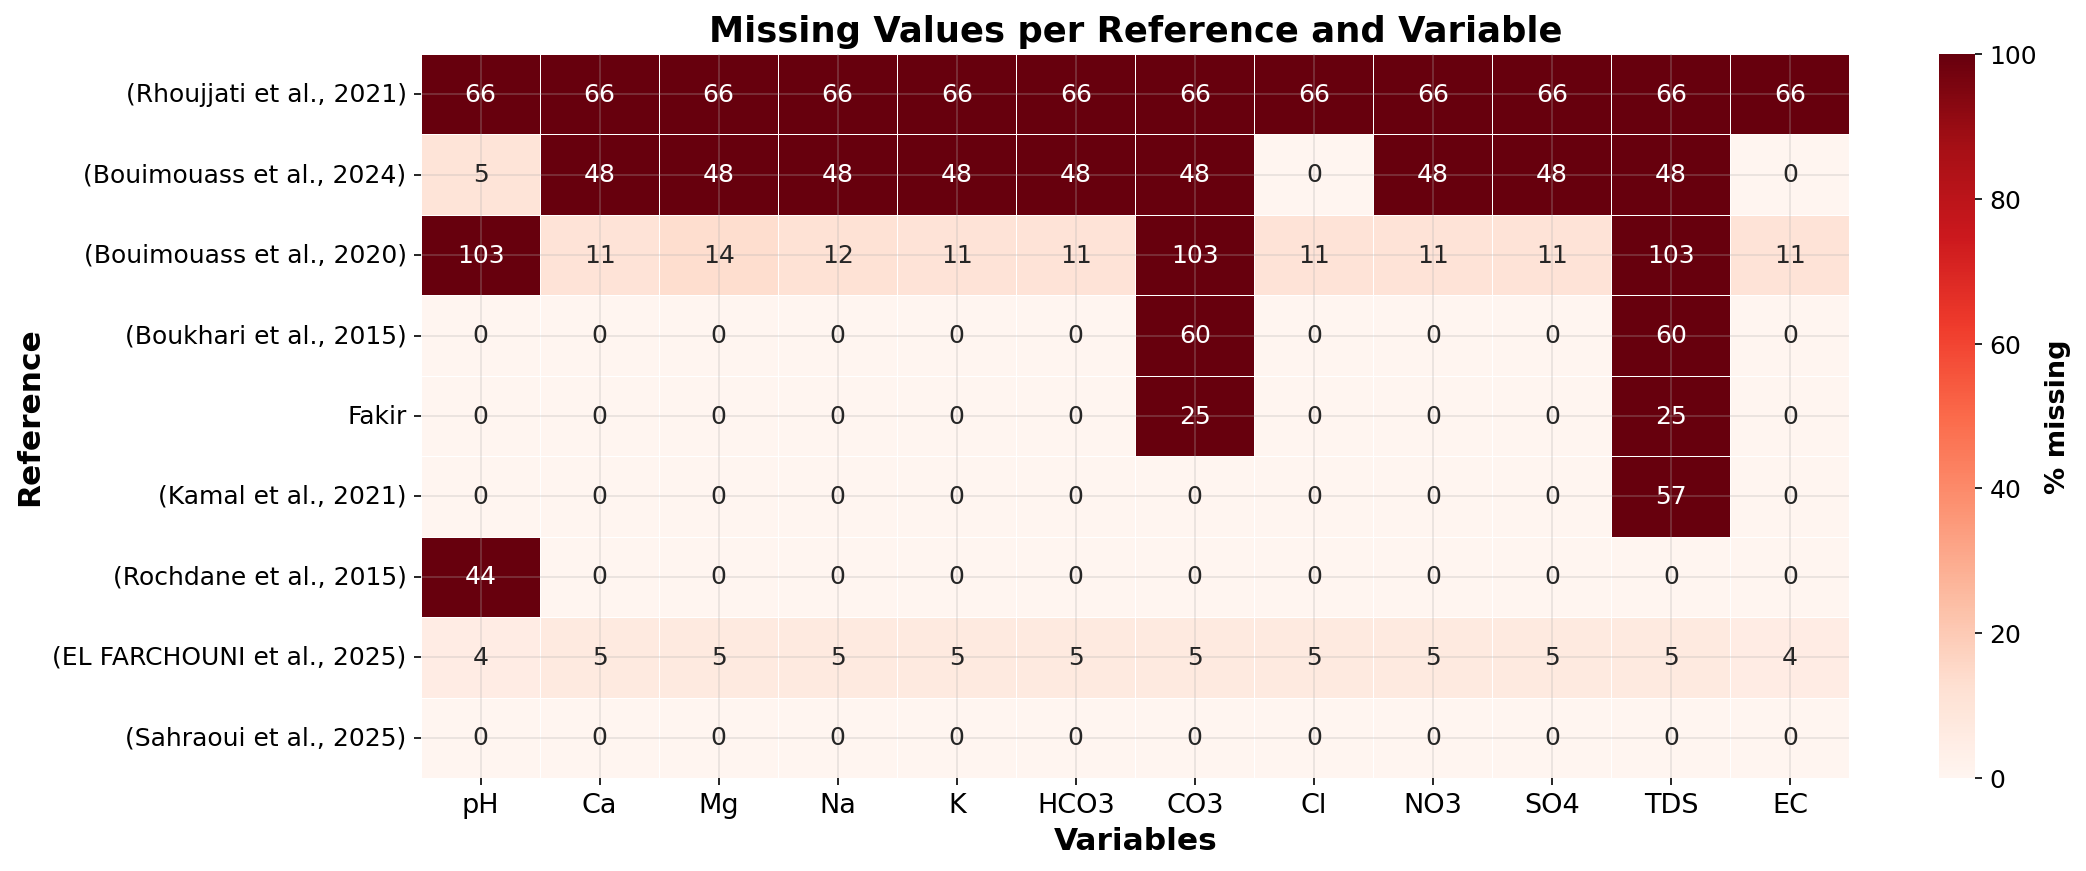

In [5]:
# ── 3.2  Missing values matrix per Reference ─────────────────────────

# Variables to inspect (keep only those present in the dataframe)
vars_ = ["pH", "Ca (mg/L)", "Mg (mg/L)", "Na (mg/L)", "K (mg/L)",
         "HCO3 (mg/L)", "CO3 (mg/L)", "Cl (mg/L)", "NO3 (mg/L)",
         "SO4 (mg/L)", "TDS (mg/L)", "EC (μS/cm)"]
vars_ = [c for c in vars_ if c in df_raw.columns]

# Missing counts per Reference × Variable
miss_counts = df_raw.groupby("Reference")[vars_].apply(lambda g: g.isna().sum())

# Denominator: number of rows per Reference
n_per_ref = df_raw.groupby("Reference").size()

# Missing fractions (%)
miss_pct = miss_counts.div(n_per_ref, axis=0) * 100

# Order references by overall missingness (descending)
order = miss_pct.mean(axis=1).sort_values(ascending=False).index
miss_pct = miss_pct.loc[order]
miss_counts = miss_counts.loc[order]

# Short labels for x-axis
short_labels = [c.replace(" (mg/L)", "").replace(" (μS/cm)", "") for c in vars_]

# Plot
fig, ax = plt.subplots(figsize=(15, max(6, 0.55 * len(miss_pct))))
sns.heatmap(
    miss_pct,
    cmap="Reds",
    annot=miss_counts.values,   # show raw counts in each cell
    fmt="d",
    linewidths=0.4,
    linecolor="white",
    cbar_kws={"label": "% missing"},
    xticklabels=short_labels,
    annot_kws={"size": 12},
    ax=ax,
)
ax.set_title("Missing Values per Reference and Variable",
             fontsize=17, fontweight="bold")
ax.set_xlabel("Variables", fontsize=15, fontweight="bold")
ax.set_ylabel("Reference", fontsize=15, fontweight="bold")
ax.tick_params(axis="x", labelsize=13)
ax.tick_params(axis="y", labelsize=12)

# Colorbar styling
cbar = ax.collections[0].colorbar
cbar.ax.tick_params(labelsize=12)
cbar.set_label("% missing", fontsize=13, fontweight="bold")

plt.tight_layout()
plt.savefig(DIR_FIGURES / "QC_missing_matrix_per_reference.png")
plt.show()

### <font color='orange'> **5) Keep the samples with all seven major ions** </font>

In [6]:
# ── 3.3  Keep only samples with complete major ions ──────────────────
# Multivariate analyses need complete records: no imputation (Haselbeck et al., 2019)

# Metadata columns to carry along
META_COLS = ["Reference", "SampleID", "Type", "Sampling date", "X", "Y"]
META_COLS = [c for c in META_COLS if c in df_raw.columns]

# Filter: all 7 major ions must be non-null
mask = df_raw[MAJOR_IONS].notna().all(axis=1)
df = df_raw.loc[mask, META_COLS + MAJOR_IONS].copy().reset_index(drop=True)

print(f"Samples before filtering : {len(df_raw)}")
print(f"Samples after filtering  : {len(df)}  (complete major ions)")
print(f"Samples removed          : {len(df_raw) - len(df)}")

print(f"\nNew dataframe 'df' - shape: {df.shape}")
print(f"Columns: {list(df.columns)}")

print(f"\n── Sample types remaining ─────────────────────────────────")
print(df["Type"].value_counts().to_string())

print(f"\n── References remaining ───────────────────────────────────")
for ref in df["Reference"].unique():
    print(f"  {ref:<40s} ({(df['Reference']==ref).sum()} samples)")

print(f"\n── Preview ────────────────────────────────────────────────")
display(df.head(10))

# ── Check against the article ────────────────────────────────────────
assert len(df_raw) == 540, "the article uses 540 samples"
assert len(df) == 406, "the article uses 406 complete samples"
print("\n✓ Matches the article: 540 samples in, 406 complete samples out.")

Samples before filtering : 540
Samples after filtering  : 406  (complete major ions)
Samples removed          : 134

New dataframe 'df' - shape: (406, 13)
Columns: ['Reference', 'SampleID', 'Type', 'Sampling date', 'X', 'Y', 'Ca (mg/L)', 'Mg (mg/L)', 'Na (mg/L)', 'K (mg/L)', 'HCO3 (mg/L)', 'Cl (mg/L)', 'SO4 (mg/L)']

── Sample types remaining ─────────────────────────────────
Type
Groundwater    305
Spring          49
Stream          40
Snow             3
Dam              2
Rain             2
Irrigation       2
Tributary        2
Lac              1

── References remaining ───────────────────────────────────
  (EL FARCHOUNI et al., 2025)              (69 samples)
  (Kamal et al., 2021)                     (57 samples)
  (Rochdane et al., 2015)                  (44 samples)
  (Sahraoui et al., 2025)                  (63 samples)
  (Bouimouass et al., 2020)                (88 samples)
  (Boukhari et al., 2015)                  (60 samples)
  Fakir                                    (25 s

,Reference,SampleID,Type,Sampling date,X,Y,Ca (mg/L),Mg (mg/L),Na (mg/L),K (mg/L),HCO3 (mg/L),Cl (mg/L),SO4 (mg/L)
0,"(EL FARCHOUNI et al., 2025)",S5,Lac,2025-01-10 00:00:00,266236.0,469982.0,26.4,2.88,75.0,1.0,274.5,14.200,3.460
1,"(EL FARCHOUNI et al., 2025)",S6,Spring,2025-01-10 00:00:00,269982.0,472108.0,48.0,4.80,5.0,5.0,164.7,3.550,3.249
2,"(EL FARCHOUNI et al., 2025)",S7,Spring,2025-01-10 00:00:00,269194.0,77219.0,140.8,4.80,10.0,10.0,427.0,7.100,27.690
3,"(EL FARCHOUNI et al., 2025)",S8,Spring,2025-01-11 00:00:00,279700.0,478756.0,51.2,7.68,5.0,2.0,170.8,7.100,12.520
4,"(EL FARCHOUNI et al., 2025)",S9,Spring,2025-01-11 00:00:00,280089.0,478353.0,88.0,12.96,10.0,5.0,262.3,10.650,13.580
5,"(EL FARCHOUNI et al., 2025)",S10,Stream,2025-01-11 00:00:00,280230.0,478266.0,32.0,5.28,5.0,2.0,122.0,14.200,10.620
6,"(EL FARCHOUNI et al., 2025)",S11,Stream,2025-01-11 00:00:00,283490.0,474694.0,24.0,9.60,5.0,1.0,85.4,10.650,6.621
7,"(EL FARCHOUNI et al., 2025)",S12,Stream,2025-01-11 00:00:00,281319.0,470656.0,20.8,5.28,5.0,1.0,85.4,5.325,0.931
8,"(EL FARCHOUNI et al., 2025)",S13,Stream,2025-01-11 00:00:00,284544.0,472534.0,27.2,6.24,4.0,1.0,79.3,7.100,13.360
9,"(EL FARCHOUNI et al., 2025)",S14,Stream,2025-01-11 00:00:00,284177.0,472933.0,22.4,11.04,5.0,1.0,91.5,7.100,6.990



✓ Matches the article: 540 samples in, 406 complete samples out.


### <font color='orange'> **6) Export** </font>

In [7]:
# ── Save the 406 complete samples for the next notebook ─────────────
out_path = DIR_INTERMED / "data_complete_major_ions.xlsx"
df.to_excel(out_path, index=False, sheet_name="Complete_Samples")

print(f"Saved: {out_path.relative_to(ROOT)}")
print(f"Shape: {df.shape[0]} samples × {df.shape[1]} columns")

Saved: outputs\intermediate\data_complete_major_ions.xlsx
Shape: 406 samples × 13 columns


---
**Output:** `outputs/intermediate/data_complete_major_ions.xlsx` (406 samples)

**Next:** `02_preprocessing.ipynb` (unit conversion mg/L → meq/L → relative % → z-score; Figure 3)